# 03 — Results

Tables and figures of the article, computed from the files in `results/`.

In [1]:
from temporal_core import *

RESULTS = load_results(CFG)
IMPORTANCE = load_importance(CFG)

## Yearly stability and data quality (Table 2)

In [2]:
TABLE2 = yearly_stability(CFG)

Table 2 — yearly stability and data quality


      Output_POA_ratio  Peak_output_pct  r_POA_P  Annual_POA_kWh_m2  Missing_target_h  Outage_h  Valid_daytime_h
Year                                                                                                            
2016             18.28             89.3    0.970             1074.7               457         0             3968
2017             18.36             89.0    0.980             1021.6               156         0             4265
2018             17.75             87.0    0.936             1179.4                57         0             4365
2019             17.85             87.2    0.978             1129.8               227         0             4191
2020             17.57             86.2    0.990             1142.7                 1         0             4424
2021             17.24             83.9    0.969             1102.8               265       129             4057

Coefficient of variation of the output/POA ratio: 0.024


## Outage detection: threshold sensitivity

In [3]:
OUTAGE_SENS = outage_threshold_sensitivity(CFG)

Outage threshold sensitivity


hours  daytime_hours  days  years             
128    98             7     (2021,)               72
129    99             7     (2021,)               54
130    100            7     (2021,)               36
131    101            8     (2021,)               21
132    102            9     (2020, 2021)           9
133    103            10    (2018, 2020, 2021)     6
137    107            9     (2020, 2021)          12
141    111            13    (2018, 2020, 2021)     6
152    108            8     (2021,)                9
153    109            8     (2021,)                6
155    111            9     (2020, 2021)           6
                      10    (2018, 2020, 2021)     3
159    115            13    (2018, 2020, 2021)     3


## Daily block bootstrap (Table 5)

In [4]:
BOOT = bootstrap_compare(CFG)

Daily block bootstrap (5,000 resamples, mask: Eval_Main)


      Family                                Comparison   dRMSE  dRMSE_lo  dRMSE_hi  p_RMSE  Signif_RMSE    dMAE  dMAE_lo  dMAE_hi  p_MAE  Signif_MAE  n_days
vs_reference                  MLR[A_5yr] − kPOA[A_5yr] -0.0064   -0.0085   -0.0042  0.0000         True  0.0001  -0.0011   0.0012 0.9168       False     336
vs_reference                  KNN[A_5yr] − kPOA[A_5yr] -0.0265   -0.0344   -0.0183  0.0000         True -0.0073  -0.0104  -0.0045 0.0000        True     336
vs_reference         RandomForest[A_5yr] − kPOA[A_5yr] -0.0235   -0.0327   -0.0148  0.0000         True -0.0106  -0.0136  -0.0080 0.0000        True     336
vs_reference              XGBoost[A_5yr] − kPOA[A_5yr] -0.0274   -0.0366   -0.0188  0.0000         True -0.0113  -0.0144  -0.0087 0.0000        True     335
vs_reference                  SVR[A_5yr] − kPOA[A_5yr] -0.0253   -0.0324   -0.0188  0.0000         True -0.0102  -0.0127  -0.0081 0.0000        True     336
vs_reference                 LSTM[A_5yr] − kPOA[A_5yr] -0.

## Bootstrap including the outage hours (Table A3)

In [5]:
BOOT_FULL = bootstrap_compare(CFG, mask_col="Eval_Full")

Daily block bootstrap (5,000 resamples, mask: Eval_Full)


      Family                                Comparison   dRMSE  dRMSE_lo  dRMSE_hi  p_RMSE  Signif_RMSE    dMAE  dMAE_lo  dMAE_hi  p_MAE  Signif_MAE  n_days
vs_reference                  MLR[A_5yr] − kPOA[A_5yr] -0.0015   -0.0049    0.0006  0.1976        False  0.0005  -0.0007   0.0017 0.4340       False     341
vs_reference                  KNN[A_5yr] − kPOA[A_5yr] -0.0103   -0.0201   -0.0050  0.0000         True -0.0070  -0.0101  -0.0043 0.0000        True     341
vs_reference         RandomForest[A_5yr] − kPOA[A_5yr] -0.0099   -0.0188   -0.0048  0.0000         True -0.0104  -0.0133  -0.0079 0.0000        True     341
vs_reference              XGBoost[A_5yr] − kPOA[A_5yr] -0.0111   -0.0204   -0.0057  0.0000         True -0.0110  -0.0140  -0.0085 0.0000        True     340
vs_reference                  SVR[A_5yr] − kPOA[A_5yr] -0.0107   -0.0189   -0.0061  0.0000         True -0.0100  -0.0124  -0.0079 0.0000        True     341
vs_reference                 LSTM[A_5yr] − kPOA[A_5yr] -0.

## Main results and training-history length (Tables 4 and 7)

In [6]:
TABLES = article_tables(CFG, RESULTS)

Article tables


Main results (case A, valid daytime hours):
                         R2  nRMSE_pct  nMAE_pct  MAPE_pct    Bias    SS  Train_s  R2_incl_outage  nRMSE_incl_outage_pct
Model                                                                                                                   
XGBoost               0.988       2.52      1.22       6.9  0.0069  0.52      2.5           0.882                   7.98
KNN                   0.987       2.61      1.62      10.2  0.0056  0.50      0.1           0.880                   8.04
SVR                   0.986       2.72      1.32       6.6  0.0101  0.48     48.7           0.881                   8.01
LSTM          0.985 ± 0.001       2.89      1.35       8.2  0.0063  0.45     67.7           0.879                   8.09
RandomForest          0.984       2.91      1.28       7.2  0.0066  0.45     52.1           0.879                   8.09
MLR                   0.961       4.62      2.35      13.6  0.0138  0.12      0.1           0.852            

## Friedman + Wilcoxon/Holm (Table 6)

In [7]:
FR_RMSE_W = friedman_compare(CFG, metric="RMSE", block="W")
FR_MAE_W  = friedman_compare(CFG, metric="MAE",  block="W")

Friedman + Wilcoxon/Holm — RMSE, block = week (n = 51), A_5yr


Mean rank (1 = best):
XGBoost         2.47
SVR             2.69
RandomForest    2.76
LSTM            3.47
KNN             4.73
kPOA            5.88
MLR             6.00

Friedman χ² = 152.4, p = 2.46e-30 | Iman–Davenport F = 49.58, p = 3.80e-42

Pairwise Wilcoxon (Holm-adjusted):
                  Pair  median_diff  a_better_blocks_pct      p  p_Holm  Signif
             MLR − SVR       0.0146               3.9216 0.0000  0.0000    True
            kPOA − SVR       0.0128               3.9216 0.0000  0.0000    True
         MLR − XGBoost       0.0132               1.9608 0.0000  0.0000    True
        kPOA − XGBoost       0.0147               7.8431 0.0000  0.0000    True
   kPOA − RandomForest       0.0116               3.9216 0.0000  0.0000    True
    MLR − RandomForest       0.0135               7.8431 0.0000  0.0000    True
            MLR − LSTM       0.0118               9.8039 0.0000  0.0000    True
             MLR − KNN       0.0087              13.7255 0.0000  0.0000    True

Friedman + Wilcoxon/Holm — MAE, block = week (n = 51), A_5yr


Mean rank (1 = best):
XGBoost         2.37
RandomForest    2.75
SVR             2.78
LSTM            3.63
KNN             4.82
kPOA            5.65
MLR             6.00

Friedman χ² = 144.6, p = 1.07e-28 | Iman–Davenport F = 44.79, p = 5.54e-39

Pairwise Wilcoxon (Holm-adjusted):
                  Pair  median_diff  a_better_blocks_pct      p  p_Holm  Signif
             MLR − SVR       0.0083               1.9608 0.0000  0.0000    True
            kPOA − SVR       0.0065               5.8824 0.0000  0.0000    True
        kPOA − XGBoost       0.0070               7.8431 0.0000  0.0000    True
         MLR − XGBoost       0.0087               3.9216 0.0000  0.0000    True
   kPOA − RandomForest       0.0065               3.9216 0.0000  0.0000    True
    MLR − RandomForest       0.0084               5.8824 0.0000  0.0000    True
            MLR − LSTM       0.0066              13.7255 0.0000  0.0000    True
         KNN − XGBoost       0.0044              15.6863 0.0000  0.0001    True

### Sensitivity: daily blocks, and days with daily POA < 500 Wh/m² removed

In [8]:
FR_RMSE_D     = friedman_compare(CFG, metric="RMSE", block="D")
FR_RMSE_D_POA = friedman_compare(CFG, metric="RMSE", block="D", min_daily_poa=500)

Friedman + Wilcoxon/Holm — RMSE, block = day (n = 334), A_5yr


Mean rank (1 = best):
XGBoost         2.81
RandomForest    2.89
SVR             3.09
LSTM            3.78
KNN             5.05
MLR             5.12
kPOA            5.26

Friedman χ² = 535.4, p = 2.02e-112 | Iman–Davenport F = 121.39, p = 5.08e-131

Pairwise Wilcoxon (Holm-adjusted):
                  Pair  median_diff  a_better_blocks_pct      p  p_Holm  Signif
            kPOA − SVR       0.0061              17.0659 0.0000  0.0000    True
             MLR − SVR       0.0081              18.2635 0.0000  0.0000    True
         MLR − XGBoost       0.0078              18.8623 0.0000  0.0000    True
   kPOA − RandomForest       0.0056              16.4671 0.0000  0.0000    True
        kPOA − XGBoost       0.0060              17.3653 0.0000  0.0000    True
    MLR − RandomForest       0.0087              20.0599 0.0000  0.0000    True
         KNN − XGBoost       0.0054              19.1617 0.0000  0.0000    True
            MLR − LSTM       0.0072              29.0419 0.0000  0.0000    T

   days with POA < 500 Wh/m² dropped: 273 / 334 days kept


Friedman + Wilcoxon/Holm — RMSE, block = day (n = 273), A_5yr


Mean rank (1 = best):
XGBoost         2.73
RandomForest    2.85
SVR             2.99
LSTM            3.88
kPOA            5.03
KNN             5.05
MLR             5.47

Friedman χ² = 483.4, p = 3.15e-101 | Iman–Davenport F = 113.88, p = 3.37e-120

Pairwise Wilcoxon (Holm-adjusted):
                  Pair  median_diff  a_better_blocks_pct      p  p_Holm  Signif
             MLR − SVR       0.0111              12.0879 0.0000  0.0000    True
         MLR − XGBoost       0.0109              14.2857 0.0000  0.0000    True
            kPOA − SVR       0.0061              19.0476 0.0000  0.0000    True
    MLR − RandomForest       0.0110              14.2857 0.0000  0.0000    True
   kPOA − RandomForest       0.0049              19.0476 0.0000  0.0000    True
        kPOA − XGBoost       0.0056              20.5128 0.0000  0.0000    True
         KNN − XGBoost       0.0057              17.5824 0.0000  0.0000    True
            MLR − LSTM       0.0093              24.5421 0.0000  0.0000    T

### Case B

In [9]:
FR_RMSE_W_B = friedman_compare(CFG, metric="RMSE", block="W", case=CFG.case_short)
FR_MAE_W_B  = friedman_compare(CFG, metric="MAE",  block="W", case=CFG.case_short)

Friedman + Wilcoxon/Holm — RMSE, block = week (n = 51), B_1yr


Mean rank (1 = best):
SVR             2.29
RandomForest    2.47
XGBoost         2.49
LSTM            4.10
KNN             4.92
MLR             5.47
kPOA            6.25

Friedman χ² = 170.9, p = 2.95e-34 | Iman–Davenport F = 63.22, p = 2.06e-50

Pairwise Wilcoxon (Holm-adjusted):
                  Pair  median_diff  a_better_blocks_pct      p  p_Holm  Signif
        kPOA − XGBoost       0.0142               0.0000 0.0000  0.0000    True
   kPOA − RandomForest       0.0137               0.0000 0.0000  0.0000    True
            kPOA − SVR       0.0128               0.0000 0.0000  0.0000    True
         MLR − XGBoost       0.0122               0.0000 0.0000  0.0000    True
             MLR − SVR       0.0120               1.9608 0.0000  0.0000    True
    MLR − RandomForest       0.0106               3.9216 0.0000  0.0000    True
           kPOA − LSTM       0.0079              13.7255 0.0000  0.0000    True
            kPOA − MLR       0.0040              19.6078 0.0000  0.0000    True

Friedman + Wilcoxon/Holm — MAE, block = week (n = 51), B_1yr


Mean rank (1 = best):
RandomForest    2.18
XGBoost         2.37
SVR             2.41
LSTM            4.53
KNN             5.22
MLR             5.24
kPOA            6.06

Friedman χ² = 175.1, p = 3.78e-35 | Iman–Davenport F = 66.85, p = 1.90e-52

Pairwise Wilcoxon (Holm-adjusted):
                  Pair  median_diff  a_better_blocks_pct      p  p_Holm  Signif
        kPOA − XGBoost       0.0100               0.0000 0.0000  0.0000    True
   kPOA − RandomForest       0.0098               0.0000 0.0000  0.0000    True
    MLR − RandomForest       0.0073               0.0000 0.0000  0.0000    True
            kPOA − SVR       0.0080               0.0000 0.0000  0.0000    True
             MLR − SVR       0.0070               0.0000 0.0000  0.0000    True
         MLR − XGBoost       0.0073               0.0000 0.0000  0.0000    True
            kPOA − MLR       0.0011              15.6863 0.0000  0.0000    True
        XGBoost − LSTM      -0.0054              88.2353 0.0000  0.0001    True

## Effect of the outage (Table 8)

In [10]:
OUTAGE = outage_effect(CFG)

Effect of the outage on the metrics (case A)


              outage_h  outage_h_pct  sq_error_share_pct  RMSE_incl_outage  RMSE_excl_outage
Model                                                                                       
kPOA                99        2.3821             67.2474            0.0908            0.0526
MLR                 99        2.3821             73.9139            0.0893            0.0462
KNN                 99        2.3821             89.6972            0.0804            0.0261
RandomForest        99        2.3821             87.3783            0.0809            0.0291
XGBoost             99        2.3855             90.2433            0.0798            0.0252
SVR                 99        2.3821             88.7086            0.0801            0.0272
LSTM                99        2.3890             87.4280            0.0815            0.0293


## Daily output in the test year (Figure 1)

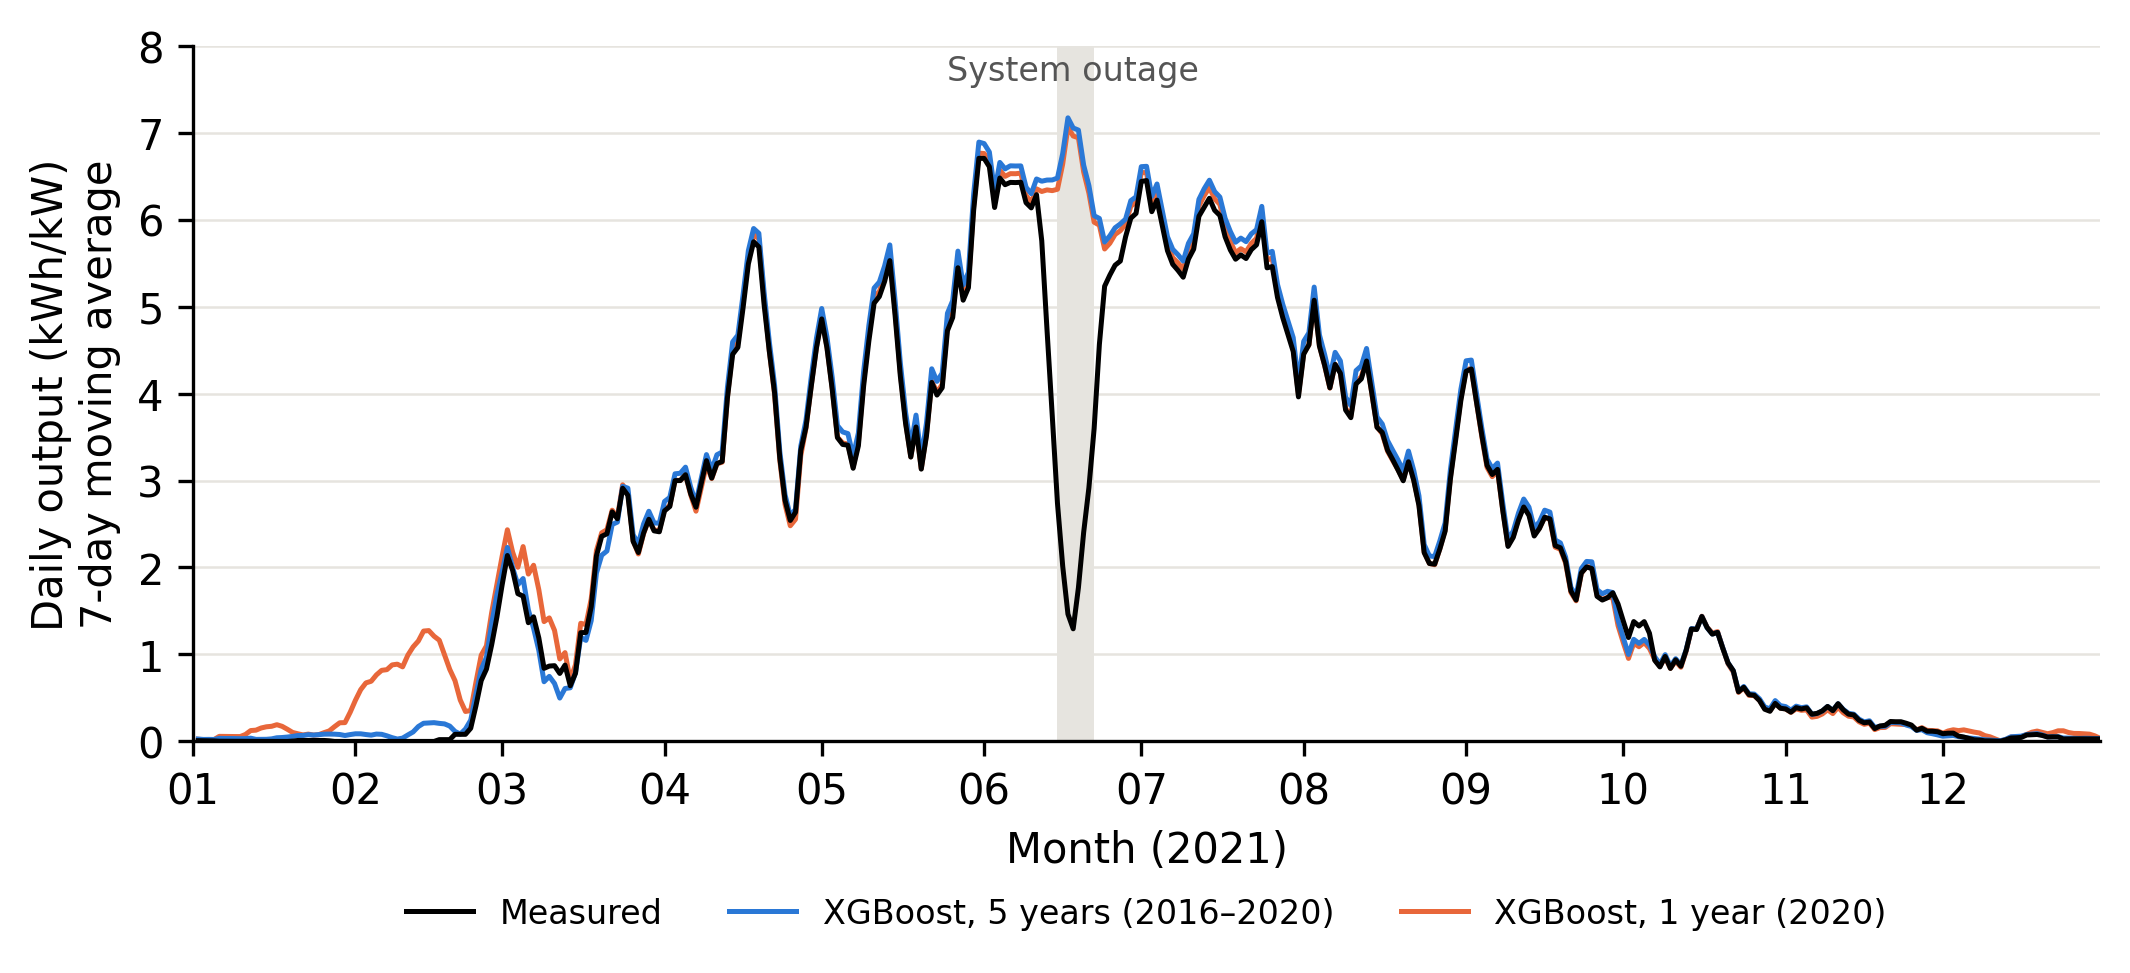

In [11]:
FIG1 = plot_daily_energy("XGBoost", CFG)

In [12]:
# February 2021, case B: measured vs predicted daily output (kWh/kW)
b = load_predictions("XGBoost", CFG, CFG.case_short)
g = b.groupby(b[CFG.time_col].dt.date)[["y_true", "y_pred"]].sum()
g.index = pd.to_datetime(g.index)
print(g[g.index.month == 2].describe().round(2))

       y_true  y_pred
count   28.00   28.00
mean     0.18    0.92
std      0.53    0.64
min      0.00    0.06
25%      0.00    0.46
50%      0.00    0.82
75%      0.00    1.23
max      2.02    2.50


## Monthly errors (Figure 2)

Monthly errors (Eval_Main)


Monthly RMSE:
       kPOA|A_5yr  kPOA|B_1yr  MLR|A_5yr  MLR|B_1yr  KNN|A_5yr  KNN|B_1yr  RandomForest|A_5yr  RandomForest|B_1yr  XGBoost|A_5yr  XGBoost|B_1yr  SVR|A_5yr  SVR|B_1yr  LSTM|A_5yr  LSTM|B_1yr
Month                                                                                                                                                                                        
1          0.0640      0.0640     0.0478     0.0563     0.0130     0.0308              0.0137              0.0377         0.0136         0.0374     0.0174     0.0350      0.0079      0.0411
2          0.1994      0.1993     0.1705     0.1885     0.0307     0.1105              0.0458              0.1553         0.0348         0.1531     0.0740     0.1457      0.0299      0.1016
3          0.0675      0.0675     0.0572     0.0630     0.0482     0.0527              0.0617              0.0529         0.0531         0.0521     0.0436     0.0550      0.0652      0.0559
4          0.0236      0.0236     0.

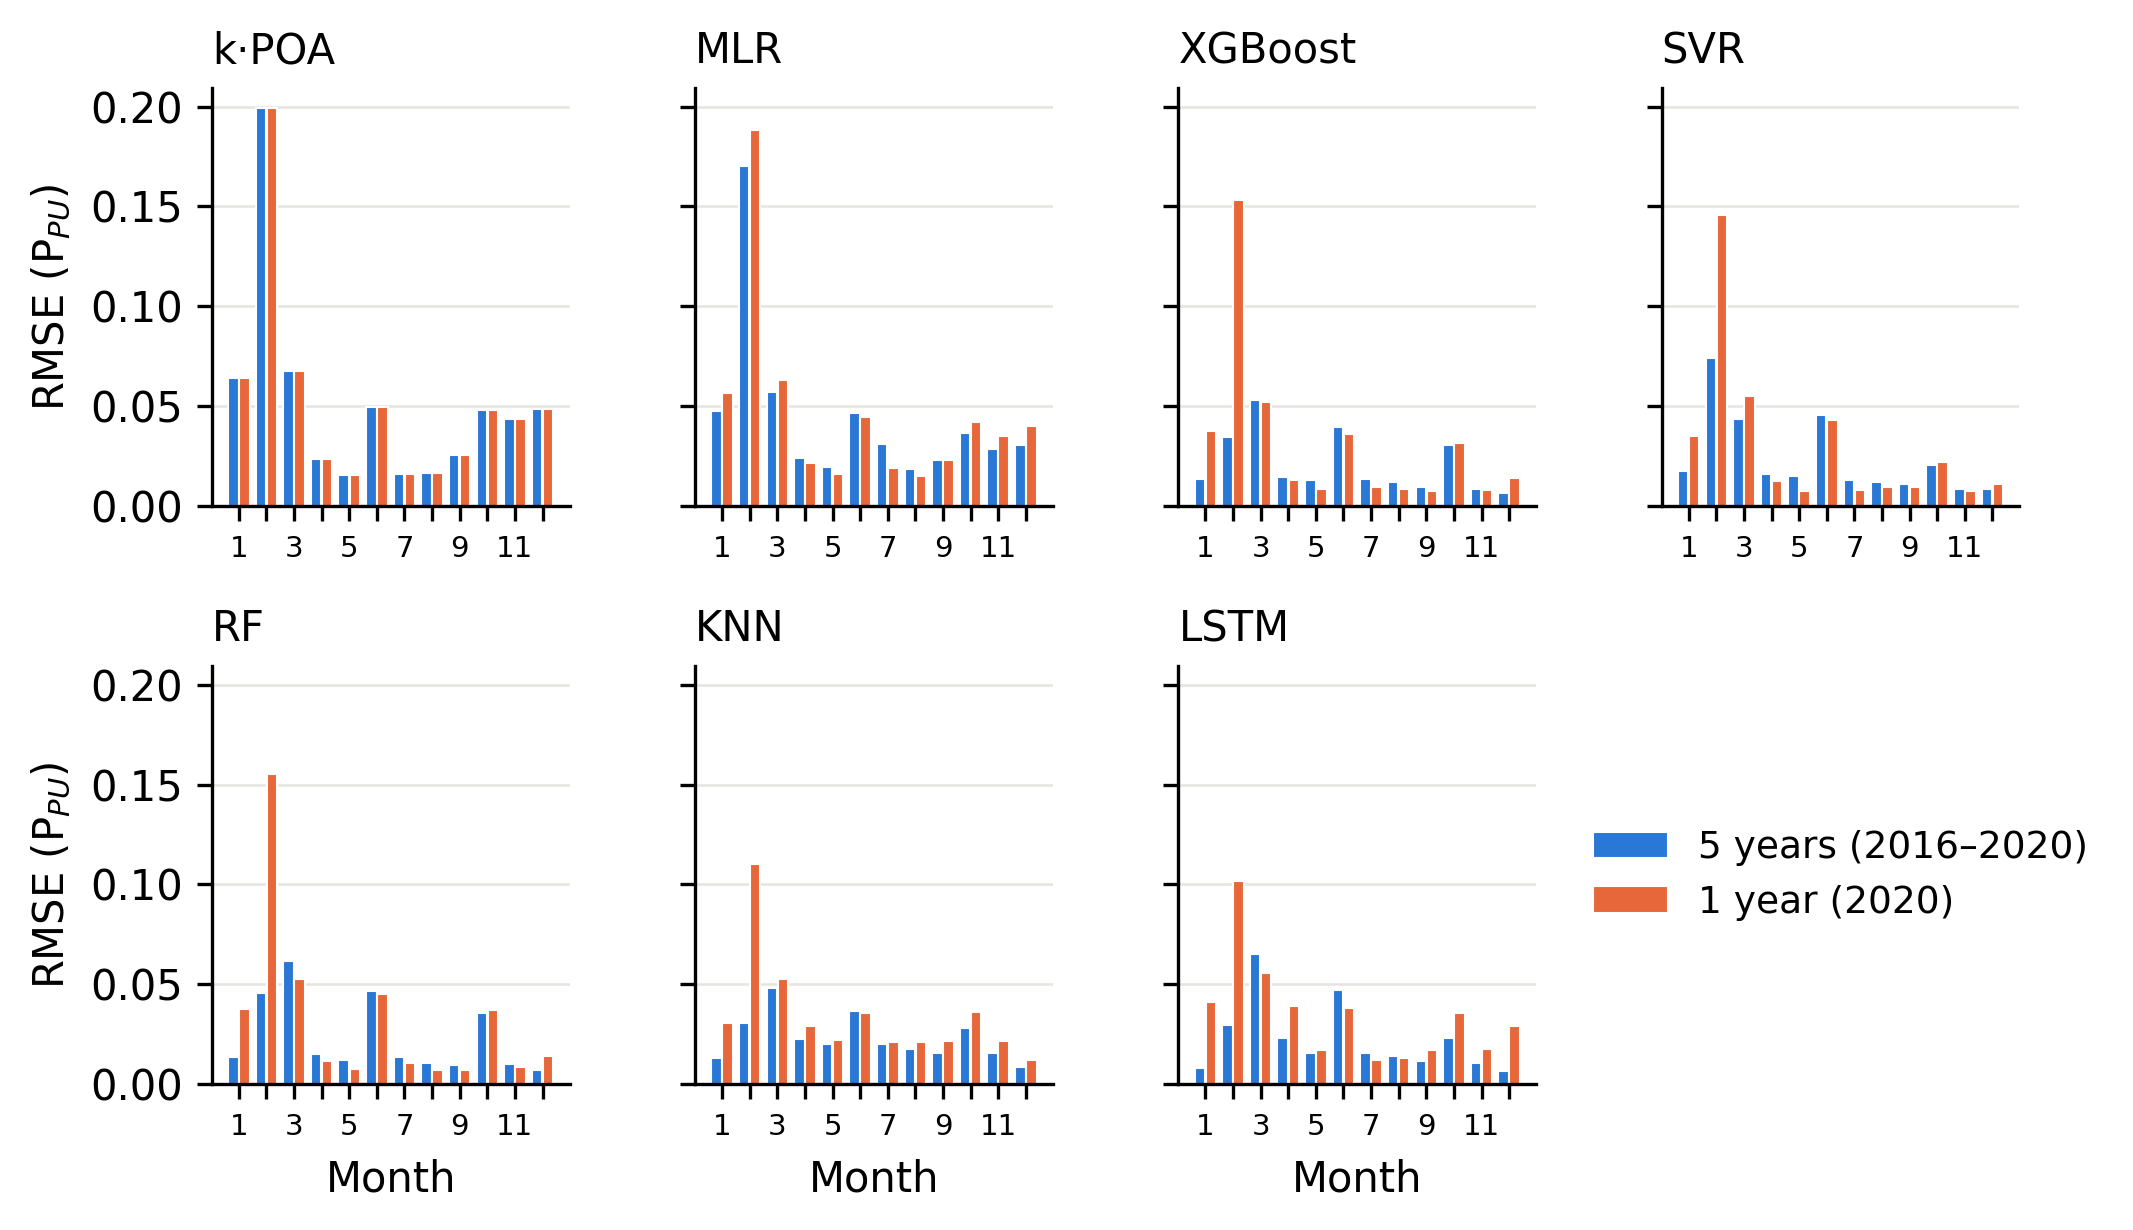

In [13]:
MONTHLY = monthly_errors(CFG)
FIG2 = plot_monthly_rmse(cfg=CFG)

## Permutation importance (Table 9)

In [14]:
IMP_TABLES = importance_table(IMPORTANCE, CFG)

Permutation importance (drop in R²)



A_5yr
Model                    KNN   LSTM    MLR  RandomForest    SVR  XGBoost
Feature                                                                 
Irradiance_POA         0.472  0.984  1.054         1.760  1.338    0.939
GHI                    0.287  0.227  0.148         0.079  0.258    0.138
Temp_Ambient           0.037  0.012  0.003         0.051  0.027    0.011
HOUR_SIN               0.030  0.005  0.000         0.001  0.030    0.003
GHI_lag3h                NaN  0.026    NaN           NaN    NaN    0.000
Irradiance_POA_lag1h     NaN  0.023    NaN           NaN    NaN    0.002
Temp_Ambient_lag24h      NaN  0.016    NaN           NaN    NaN    0.022
GHI_lag2h                NaN  0.021    NaN           NaN    NaN   -0.000
GHI_lag1h                NaN  0.015    NaN           NaN    NaN    0.000
GHI_lag24h               NaN  0.013    NaN           NaN    NaN    0.000
MONTH_COS              0.008  0.013 -0.000         0.000  0.007    0.001
Irradiance_POA_lag2h     NaN  0.010    NaN  